In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import time
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
import xgboost as xgb
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 42
FIGURES_PATH = '../outputs/figures/'
MODELS_PATH  = '../outputs/models/'

In [4]:
df = pd.read_csv('../data/processed/D1_cleaned.csv')
print(f"Shape: {df.shape}")

# dropping a duplicate column: InitialYear and DaysSinceReported are perfectly correlated (-1.00), we need to drop InitialYear
df = df.drop(columns=['InitialYear'])
print(f"Shape after dropping InitialYear: {df.shape}")

TARGET = 'FlagProp65'
X = df.drop(columns=[TARGET])
y = df[TARGET]

print(f"\nClass distribution:\n{y.value_counts()}")
print(f"Positive rate: {y.mean():.2%}")

Shape: (63212, 112)
Shape after dropping InitialYear: (63212, 111)

Class distribution:
FlagProp65
False    59815
True      3397
Name: count, dtype: int64
Positive rate: 5.37%


In [5]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print(f"Train: {X_train.shape}, Val: {X_val.shape}")
print(f"Train positive rate: {y_train.mean():.2%}")
print(f"Val positive rate: {y_val.mean():.2%}")

Train: (50569, 110), Val: (12643, 110)
Train positive rate: 5.37%
Val positive rate: 5.37%


In [6]:
results = {}

def evaluate(name, model, X_val, y_val):
    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1]
    acc = accuracy_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)
    auc = roc_auc_score(y_val, y_prob)
    results[name] = {'Accuracy': acc, 'F1': f1, 'AUC-ROC': auc}
    print(f"\n{'='*40}")
    print(f"{name}")
    print(f"{'='*40}")
    print(f"Accuracy: {acc:.4f}  - don't trust this")
    print(f"F1: {f1:.4f}")
    print(f"AUC-ROC: {auc:.4f}")
    print(f"\n{classification_report(y_val, y_pred, target_names=['Non-toxic','Toxic'])}")
    return model

## Baseline Models (naive, no balancing, all features)
- Train on D1 80% split
- Validate on D1 20% split (hyperparameter tuning here)
- Report: Accuracy (don’t trust it), F1, AUC-ROC
- Hyperparameter search: Optuna for Random Forest + Boosting (slow), Grid Search for Logistic Regression + Decision Tree (fast) 

### Model 1: Logistic regression

In [7]:
print("Training Logistic Regression...")
t0 = time.time()

lr_params = {
    'C': [0.01, 0.1, 1, 10],
    'solver': ['lbfgs'],
    'max_iter': [1000]
}
lr_gs = GridSearchCV(
    LogisticRegression(random_state=SEED),
    lr_params, cv=5, scoring='roc_auc', n_jobs=-1, verbose=0
)
lr_gs.fit(X_train, y_train)
print(f"Best params: {lr_gs.best_params_}  ({time.time()-t0:.0f}s)")
lr_best = evaluate("Logistic Regression", lr_gs.best_estimator_, X_val, y_val)

Training Logistic Regression...
Best params: {'C': 1, 'max_iter': 1000, 'solver': 'lbfgs'}  (93s)

Logistic Regression
Accuracy: 0.9580  - don't trust this
F1: 0.4706
AUC-ROC: 0.8982

              precision    recall  f1-score   support

   Non-toxic       0.96      0.99      0.98     11964
       Toxic       0.73      0.35      0.47       679

    accuracy                           0.96     12643
   macro avg       0.85      0.67      0.72     12643
weighted avg       0.95      0.96      0.95     12643



### Model 2: Decision Tree (Grid Search)

In [8]:
print("Training Decision Tree...")
t0 = time.time()

dt_params = {
    'max_depth': [3, 5, 10, None],
    'min_samples_leaf': [1, 5, 20],
    'criterion': ['gini', 'entropy']
}
dt_gs = GridSearchCV(
    DecisionTreeClassifier(random_state=SEED),
    dt_params, cv=5, scoring='roc_auc', n_jobs=-1, verbose=0
)
dt_gs.fit(X_train, y_train)
print(f"Best params: {dt_gs.best_params_}  ({time.time()-t0:.0f}s)")
dt_best = evaluate("Decision Tree", dt_gs.best_estimator_, X_val, y_val)

Training Decision Tree...
Best params: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 20}  (8s)

Decision Tree
Accuracy: 0.9637  - don't trust this
F1: 0.5920
AUC-ROC: 0.9410

              precision    recall  f1-score   support

   Non-toxic       0.97      0.99      0.98     11964
       Toxic       0.75      0.49      0.59       679

    accuracy                           0.96     12643
   macro avg       0.86      0.74      0.79     12643
weighted avg       0.96      0.96      0.96     12643



### Model 3: Random Forest (Optuna)

In [9]:
print("Training Random Forest with Optuna (this may take a few minutes)...")
t0 = time.time()

def rf_objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=100),
        'max_depth': trial.suggest_int('max_depth', 3, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 20),
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2']),
        'random_state': SEED, 'n_jobs': -1
    }
    model = RandomForestClassifier(**params)
    score = cross_val_score(model, X_train, y_train, cv=3, scoring='roc_auc', n_jobs=-1).mean()
    return score

rf_study = optuna.create_study(direction='maximize')
rf_study.optimize(rf_objective, n_trials=20, show_progress_bar=True)
print(f"Best params: {rf_study.best_params}  ({time.time()-t0:.0f}s)")

rf_best = RandomForestClassifier(**rf_study.best_params, random_state=SEED, n_jobs=-1)
rf_best.fit(X_train, y_train)
rf_best = evaluate("Random Forest", rf_best, X_val, y_val)

Training Random Forest with Optuna (this may take a few minutes)...


  0%|          | 0/20 [00:00<?, ?it/s]

Best params: {'n_estimators': 500, 'max_depth': 18, 'min_samples_leaf': 1, 'max_features': 'sqrt'}  (99s)

Random Forest
Accuracy: 0.9663  - don't trust this
F1: 0.5731
AUC-ROC: 0.9654

              precision    recall  f1-score   support

   Non-toxic       0.97      1.00      0.98     11964
       Toxic       0.90      0.42      0.57       679

    accuracy                           0.97     12643
   macro avg       0.93      0.71      0.78     12643
weighted avg       0.96      0.97      0.96     12643



### Model 4: XGBoost (Optuna)

In [10]:
print("Training XGBoost with Optuna...")
t0 = time.time()

scale_pos = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight (imbalance ratio): {scale_pos:.1f}")

def xgb_objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=100),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'scale_pos_weight': 1,   # naive: no balancing yet
        'eval_metric': 'auc', 'use_label_encoder': False,
        'random_state': SEED, 'n_jobs': -1
    }
    model = xgb.XGBClassifier(**params)
    score = cross_val_score(model, X_train, y_train, cv=3, scoring='roc_auc', n_jobs=-1).mean()
    return score

xgb_study = optuna.create_study(direction='maximize')
xgb_study.optimize(xgb_objective, n_trials=20, show_progress_bar=True)
print(f"Best params: {xgb_study.best_params}  ({time.time()-t0:.0f}s)")

xgb_best = xgb.XGBClassifier(**xgb_study.best_params, scale_pos_weight=1, eval_metric='auc', random_state=SEED, n_jobs=-1)
xgb_best.fit(X_train, y_train)
xgb_best = evaluate("XGBoost", xgb_best, X_val, y_val)

Training XGBoost with Optuna...
scale_pos_weight (imbalance ratio): 17.6


  0%|          | 0/20 [00:00<?, ?it/s]

Best params: {'n_estimators': 200, 'max_depth': 10, 'learning_rate': 0.1235587703145121, 'subsample': 0.8645326136019944, 'colsample_bytree': 0.6083674765538075}  (70s)

XGBoost
Accuracy: 0.9696  - don't trust this
F1: 0.6821
AUC-ROC: 0.9721

              precision    recall  f1-score   support

   Non-toxic       0.98      0.99      0.98     11964
       Toxic       0.78      0.61      0.68       679

    accuracy                           0.97     12643
   macro avg       0.88      0.80      0.83     12643
weighted avg       0.97      0.97      0.97     12643



### Comparison

In [11]:
results_df = pd.DataFrame(results).T.sort_values('AUC-ROC', ascending=False)
print("\n NAIVE BASELINE COMPARISON (no balancing)")
print(results_df.to_string(float_format='{:.4f}'.format))


 NAIVE BASELINE COMPARISON (no balancing)
                     Accuracy     F1  AUC-ROC
XGBoost                0.9696 0.6821   0.9721
Random Forest          0.9663 0.5731   0.9654
Decision Tree          0.9637 0.5920   0.9410
Logistic Regression    0.9580 0.4706   0.8982


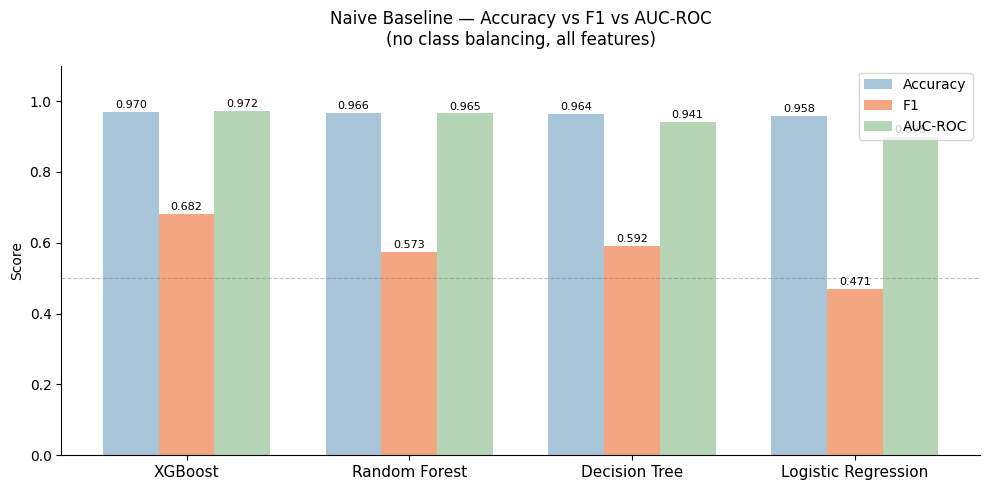

Saved: 14_naive_baseline_comparison.png


In [12]:
COLOR_NONTOXIC = '#A8C5DA'
COLOR_TOXIC = '#F4A582'
COLOR_PALETTE = ['#A8C5DA', '#F4A582', '#B5D5B5']

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(results_df))
w = 0.25
metrics = ['Accuracy', 'F1', 'AUC-ROC']
colors = COLOR_PALETTE

for i, (metric, color) in enumerate(zip(metrics, colors)):
    bars = ax.bar(x + i*w, results_df[metric], width=w, label=metric, color=color)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x + w)
ax.set_xticklabels(results_df.index, fontsize=11)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Score')
ax.set_title('Naive Baseline — Accuracy vs F1 vs AUC-ROC\n(no class balancing, all features)', pad=15)
ax.legend()
ax.axhline(0.5, color='grey', linestyle='--', linewidth=0.8, alpha=0.5)
sns.despine()
plt.tight_layout()
plt.savefig(FIGURES_PATH + '14_naive_baseline_comparison.png', dpi=150)
plt.show()
print("Saved: 14_naive_baseline_comparison.png")

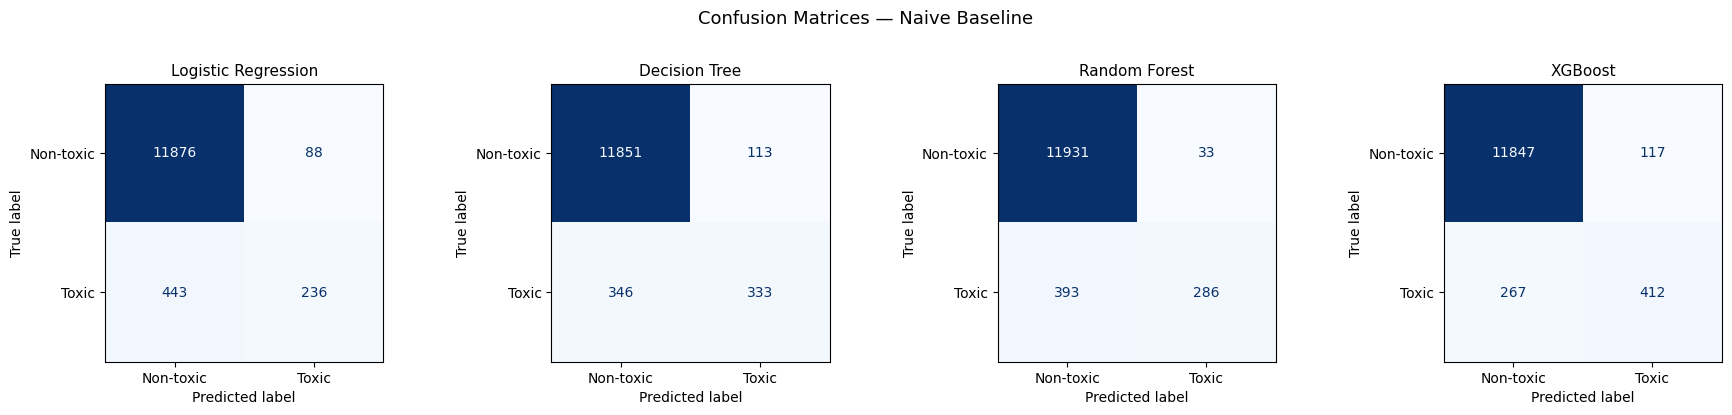

Saved: 15_confusion_matrices_naive.png


In [13]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
models_list = [
    ("Logistic Regression", lr_gs.best_estimator_),
    ("Decision Tree", dt_gs.best_estimator_),
    ("Random Forest", rf_best),
    ("XGBoost", xgb_best),
]
for ax, (name, model) in zip(axes, models_list):
    cm = confusion_matrix(y_val, model.predict(X_val))
    disp = ConfusionMatrixDisplay(cm, display_labels=['Non-toxic', 'Toxic'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name, fontsize=11)
plt.suptitle('Confusion Matrices — Naive Baseline', y=1.02, fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_PATH + '15_confusion_matrices_naive.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: 15_confusion_matrices_naive.png")

In [14]:
# save models
import joblib

joblib.dump(lr_gs.best_estimator_, MODELS_PATH + 'lr_naive.pkl')
joblib.dump(dt_gs.best_estimator_, MODELS_PATH + 'dt_naive.pkl')
joblib.dump(rf_best, MODELS_PATH + 'rf_naive.pkl')
joblib.dump(xgb_best, MODELS_PATH + 'xgb_naive.pkl')
print("All 4 models saved to outputs/models/")

All 4 models saved to outputs/models/
